In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Works when the notebook starts from the project root or notebooks folder.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "raw" / "telco_churn.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df_raw = pd.read_csv(
    DATA_PATH,
    dtype={"customerID": "string"},
)

print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")
display(df_raw.head())

Rows: 7,043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df_raw.info()

quality_report = pd.DataFrame({
    "data_type": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "unique_values": df_raw.nunique(),
})

display(quality_report)

print(f"Exact duplicate rows: {df_raw.duplicated().sum():,}")
print(
    "Duplicate customer IDs:",
    df_raw["customerID"].duplicated().sum(),
)

print("\nChurn counts:")
display(df_raw["Churn"].value_counts(dropna=False))

print("\nChurn percentages:")
display(
    df_raw["Churn"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   string 
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,data_type,missing_count,unique_values
customerID,string,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


Exact duplicate rows: 0
Duplicate customer IDs: 0

Churn counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentages:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

## Train and Test Split

The target is `Churn`: Yes means the customer left, and No means
the customer stayed.

We reserve 20% of customers for the final test. The split is stratified
to preserve the churn proportion. Customer IDs are excluded from model
features because they identify records rather than describe customers.

In [4]:
from sklearn.model_selection import train_test_split

df = df_raw.copy()

# Confirm the target values and customer identifiers before splitting.
print("Target values:", df["Churn"].value_counts(dropna=False).to_dict())
print("Missing customer IDs:", df["customerID"].isna().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

if df["customerID"].isna().any() or df["customerID"].duplicated().any():
    raise ValueError("Review missing or duplicate customer IDs before splitting.")

if not df["Churn"].isin(["Yes", "No"]).all():
    raise ValueError("Review unexpected or missing Churn values before splitting.")

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print(f"\nTraining customers: {len(X_train):,}")
print(f"Test customers: {len(X_test):,}")
print(f"Training churn rate: {y_train.mean():.2%}")
print(f"Test churn rate: {y_test.mean():.2%}")

Target values: {'No': 5174, 'Yes': 1869}
Missing customer IDs: 0
Duplicate customer IDs: 0

Training customers: 5,634
Test customers: 1,409
Training churn rate: 26.54%
Test churn rate: 26.54%


## Training Data Quality and Churn Patterns

This section explores only the training data. TotalCharges is checked
for values that cannot be converted to numbers.

The patterns are descriptive and do not prove why customers leave.

In [5]:
# Create a copy for exploration.
train_eda = X_train.copy()
train_eda["Churn"] = y_train.map({0: "No", 1: "Yes"})

# Check whether TotalCharges contains text or blank values.
total_charges_numeric = pd.to_numeric(
    train_eda["TotalCharges"],
    errors="coerce",
)

invalid_total_charges = (
    train_eda["TotalCharges"].notna()
    & total_charges_numeric.isna()
)

print("Training rows:", len(train_eda))
print(
    "TotalCharges values that cannot be converted:",
    invalid_total_charges.sum(),
)

display(
    train_eda.loc[
        invalid_total_charges,
        ["tenure", "MonthlyCharges", "TotalCharges", "Churn"],
    ].head(10)
)

print("\nMissing values in the training set:")
display(
    train_eda.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
    .head(10)
)

# Churn counts and rates for selected categories.
for column in ["Contract", "InternetService", "PaymentMethod"]:
    print(f"\nChurn by {column}:")

    summary = (
        train_eda.groupby(column)["Churn"]
        .agg(
            customers="size",
            churned=lambda values: (values == "Yes").sum(),
        )
    )

    summary["churn_rate_pct"] = (
        summary["churned"] / summary["customers"] * 100
    )

    display(summary.sort_values("churn_rate_pct", ascending=False).round(2))

Training rows: 5634
TotalCharges values that cannot be converted: 8


,tenure,MonthlyCharges,TotalCharges,Churn
6670,0,73.35,,No
4380,0,20.00,,No
3826,0,25.35,,No
488,0,52.55,,No
1082,0,25.75,,No
1340,0,56.05,,No
6754,0,61.90,,No
3331,0,19.85,,No



Missing values in the training set:


,missing_count
gender,0
SeniorCitizen,0
TotalCharges,0
MonthlyCharges,0
PaymentMethod,0
PaperlessBilling,0
Contract,0
StreamingMovies,0
StreamingTV,0
TechSupport,0



Churn by Contract:


,customers,churned,churn_rate_pct
Contract,,,
Month-to-month,3102,1326,42.75
One year,1173,130,11.08
Two year,1359,39,2.87



Churn by InternetService:


,customers,churned,churn_rate_pct
InternetService,,,
Fiber optic,2483,1045,42.09
DSL,1937,362,18.69
No,1214,88,7.25



Churn by PaymentMethod:


,customers,churned,churn_rate_pct
PaymentMethod,,,
Electronic check,1891,865,45.74
Mailed check,1286,248,19.28
Bank transfer (automatic),1244,201,16.16
Credit card (automatic),1213,181,14.92


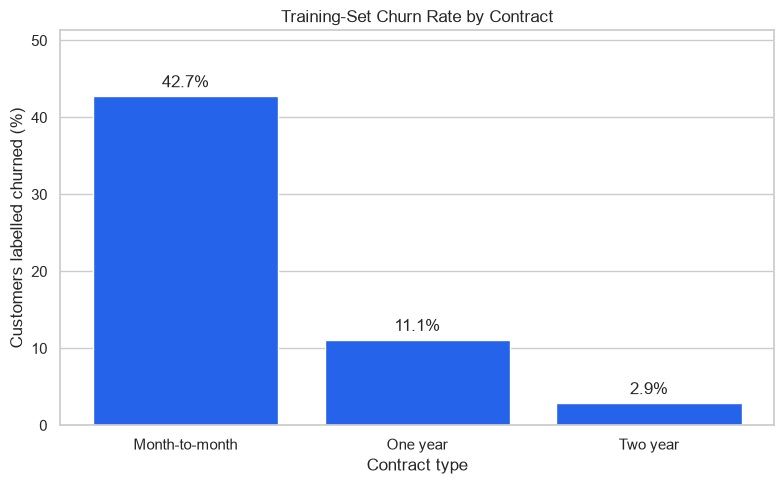

In [6]:
contract_churn = (
    train_eda.groupby("Contract")["Churn"]
    .apply(lambda values: (values == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    contract_churn.index,
    contract_churn.values,
    color="#2563eb",
)

ax.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in contract_churn.values],
    padding=4,
)

ax.set_title("Training-Set Churn Rate by Contract")
ax.set_ylabel("Customers labelled churned (%)")
ax.set_xlabel("Contract type")
ax.set_ylim(0, max(contract_churn.values) * 1.2)
ax.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(
    FIGURES / "churn_by_contract.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## Logistic Regression Baseline

This pipeline converts TotalCharges to numeric, fills missing values,
scales numeric features, and one-hot encodes categorical features.

Preprocessing is fitted only on training data. We use stratified
cross-validation to evaluate the baseline before the final test.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler


def prepare_features(frame):
    """Convert TotalCharges to numeric on a copy of the input."""
    result = frame.copy()
    result["TotalCharges"] = pd.to_numeric(
        result["TotalCharges"],
        errors="coerce",
    )
    return result


numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
]

categorical_features = [
    column
    for column in X_train.columns
    if column not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

baseline = Pipeline([
    (
        "prepare",
        FunctionTransformer(
            prepare_features,
            validate=False,
        ),
    ),
    ("preprocess", preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=42,
        ),
    ),
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

scores = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc",
        "average_precision": "average_precision",
    },
    n_jobs=-1,
    error_score="raise",
)

cv_summary = pd.DataFrame({
    "mean": {
        metric: scores[f"test_{metric}"].mean()
        for metric in [
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "average_precision",
        ]
    },
    "std": {
        metric: scores[f"test_{metric}"].std()
        for metric in [
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "average_precision",
        ]
    },
})

print("Logistic regression: 5-fold training cross-validation")
display(cv_summary.round(3))

Logistic regression: 5-fold training cross-validation


,mean,std
accuracy,0.802,0.012
precision,0.653,0.025
recall,0.543,0.041
f1,0.592,0.030
roc_auc,0.846,0.013
average_precision,0.661,0.019


## Model Comparison

Compare logistic regression and random forest using the same
five stratified cross-validation folds on the training data.

Recall measures how many churners the model identifies. Precision
measures how many predicted churners actually churned. F1 balances
the two; ROC AUC and average precision evaluate ranking performance.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer

random_forest = Pipeline([
    (
        "prepare",
        FunctionTransformer(
            prepare_features,
            validate=False,
        ),
    ),
    ("preprocess", preprocessor),
    (
        "model",
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=1,
        ),
    ),
])

metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

forest_scores = cross_validate(
    random_forest,
    X_train,
    y_train,
    cv=cv,
    scoring=metrics,
    n_jobs=-1,
    error_score="raise",
)

model_comparison = pd.DataFrame(
    {
        "Logistic regression": {
            metric: scores[f"test_{metric}"].mean()
            for metric in metrics
        },
        "Random forest": {
            metric: forest_scores[f"test_{metric}"].mean()
            for metric in metrics
        },
    }
)

print("Mean scores across five training folds")
display(model_comparison.round(3))

Mean scores across five training folds


,Logistic regression,Random forest
accuracy,0.802,0.797
precision,0.653,0.657
recall,0.543,0.495
f1,0.592,0.564
roc_auc,0.846,0.837
average_precision,0.661,0.641


## Model and Threshold Selection

Select the model with the higher mean cross-validation F1 score.
Then compare thresholds using out-of-fold training predictions.

The threshold is selected on training data. The test set remains
untouched until the final evaluation.

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_predict

# Select the model with the higher mean training cross-validation F1.
baseline_f1 = scores["test_f1"].mean()
forest_f1 = forest_scores["test_f1"].mean()

if forest_f1 > baseline_f1:
    selected_name = "Random forest"
    selected_model = random_forest
else:
    selected_name = "Logistic regression"
    selected_model = baseline

print(f"Selected model: {selected_name}")
print(f"Logistic regression CV F1: {baseline_f1:.3f}")
print(f"Random forest CV F1: {forest_f1:.3f}")

# Each training prediction comes from a model that did not train on
# that customer's fold.
train_probabilities = cross_val_predict(
    selected_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = np.arange(0.20, 0.81, 0.05)
threshold_results = []

for threshold in thresholds:
    predictions = (train_probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_train, predictions, zero_division=0
        ),
    })

threshold_table = pd.DataFrame(threshold_results)

# Highest training F1; if tied, choose the higher threshold.
best_row = threshold_table.sort_values(
    ["f1", "threshold"],
    ascending=[False, False],
).iloc[0]

selected_threshold = float(best_row["threshold"])

display(threshold_table.round(3))
print(f"Selected threshold: {selected_threshold:.2f}")

Selected model: Logistic regression
Logistic regression CV F1: 0.592
Random forest CV F1: 0.564


,threshold,precision,recall,f1
0,0.20,0.475,0.855,0.611
1,0.25,0.510,0.817,0.628
2,0.30,0.541,0.767,0.634
3,0.35,0.571,0.717,0.635
4,0.40,0.594,0.664,0.627
5,0.45,0.624,0.601,0.612
6,0.50,0.653,0.543,0.593
7,0.55,0.685,0.486,0.569
8,0.60,0.710,0.397,0.509
9,0.65,0.754,0.306,0.435


Selected threshold: 0.35


## Final Test Evaluation

The model and threshold were selected using training data. This section
fits the selected pipeline on the full training set and evaluates it
on the held-out test set.

The test set is used for final reporting, not for choosing a different
model or threshold.

Selected model: Logistic regression
Selected threshold: 0.35
Test churn rate: 26.54%


,Test score
Accuracy,0.765
Precision,0.544
Recall,0.706
F1,0.615
ROC AUC,0.842
Average precision,0.633



Classification report:
              precision    recall  f1-score   support

      Stayed       0.88      0.79      0.83      1035
     Churned       0.54      0.71      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.77      0.77      1409



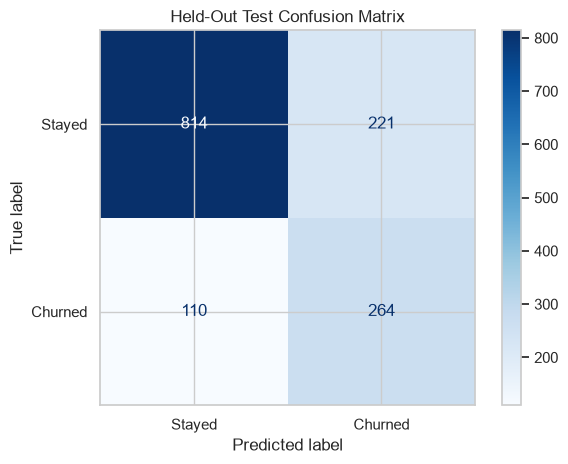

In [10]:
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Fit a fresh copy of the selected pipeline on all training data.
final_model = clone(selected_model)
final_model.fit(X_train, y_train)

test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

test_results = pd.Series({
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "ROC AUC": roc_auc_score(y_test, test_probabilities),
    "Average precision": average_precision_score(
        y_test, test_probabilities
    ),
})

print("Selected model:", selected_name)
print(f"Selected threshold: {selected_threshold:.2f}")
print(f"Test churn rate: {y_test.mean():.2%}")

display(test_results.round(3).to_frame("Test score"))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Stayed", "Churned"],
        zero_division=0,
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Blues",
    values_format="d",
)

plt.title("Held-Out Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    FIGURES / "test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## Model Feature Interpretation

Feature scores describe the fitted model, not causal effects.

For logistic regression, positive coefficients increase the model's
churn score; negative coefficients decrease it.

For random forest, impurity-based importance measures contribution to
tree splits. It can favor certain features and does not show direction.

Categorical variables are displayed as individual encoded categories.

,feature,score,absolute_score
1,numeric__tenure,-1.2413,1.2413
38,categorical__Contract_Two year,-0.7723,0.7723
15,categorical__InternetService_DSL,-0.6524,0.6524
16,categorical__InternetService_Fiber optic,0.6400,0.6400
2,numeric__MonthlyCharges,-0.5964,0.5964
36,categorical__Contract_Month-to-month,0.5793,0.5793
3,numeric__TotalCharges,0.5167,0.5167
39,categorical__PaperlessBilling_No,-0.3433,0.3433
17,categorical__InternetService_No,-0.3011,0.3011
19,categorical__OnlineSecurity_No internet service,-0.3011,0.3011


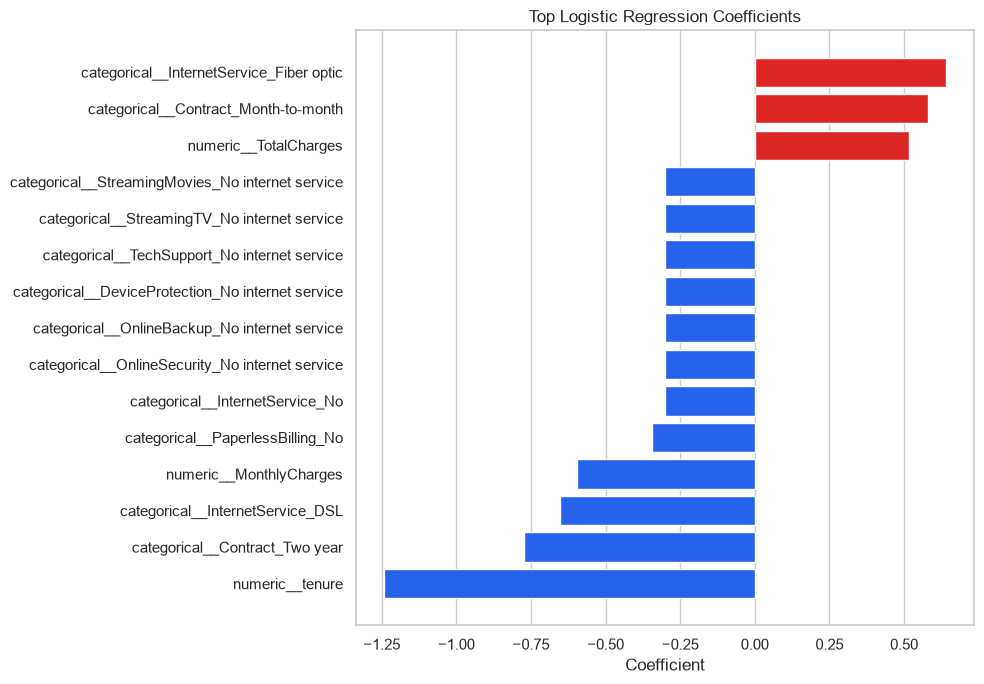

In [11]:
# Get the fitted preprocessing and model components.
fitted_preprocessor = final_model.named_steps["preprocess"]
fitted_estimator = final_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if selected_name == "Logistic regression":
    feature_scores = pd.DataFrame({
        "feature": feature_names,
        "score": fitted_estimator.coef_[0],
    })

    feature_scores["absolute_score"] = feature_scores["score"].abs()

    top_features = (
        feature_scores
        .nlargest(15, "absolute_score")
        .sort_values("score")
    )

    title = "Top Logistic Regression Coefficients"
    xlabel = "Coefficient"
    colors = [
        "#dc2626" if value > 0 else "#2563eb"
        for value in top_features["score"]
    ]

else:
    feature_scores = pd.DataFrame({
        "feature": feature_names,
        "score": fitted_estimator.feature_importances_,
    })

    top_features = (
        feature_scores
        .nlargest(15, "score")
        .sort_values("score")
    )

    title = "Top Random Forest Feature Importances"
    xlabel = "Impurity-based importance"
    colors = "#2563eb"

display(
    top_features.sort_values(
        "score",
        key=lambda values: values.abs(),
        ascending=False,
    ).round(4)
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_features["feature"],
    top_features["score"],
    color=colors,
)

ax.set_title(title)
ax.set_xlabel(xlabel)
ax.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig(
    FIGURES / "model_feature_scores.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

In [12]:
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

# Save training comparisons and held-out test results.
model_comparison.to_csv(REPORTS / "model_comparison.csv")
threshold_table.to_csv(REPORTS / "threshold_selection.csv", index=False)
test_results.to_csv(REPORTS / "test_metrics.csv", header=["score"])
feature_scores.to_csv(REPORTS / "feature_scores.csv", index=False)

print(f"Selected model: {selected_name}")
print(f"Selected threshold: {selected_threshold:.2f}")
print(f"Test precision: {test_results['Precision']:.3f}")
print(f"Test recall: {test_results['Recall']:.3f}")
print(f"Test F1: {test_results['F1']:.3f}")
print(f"Test ROC AUC: {test_results['ROC AUC']:.3f}")
print(f"\nReports saved in: {REPORTS}")

Selected model: Logistic regression
Selected threshold: 0.35
Test precision: 0.544
Test recall: 0.706
Test F1: 0.615
Test ROC AUC: 0.842

Reports saved in: /Users/rashmidragon/Desktop/customer-churn-prediction/reports


## Interpretation and Limitations

- The dataset describes a fictional telecom company.
- The test metrics report performance on a held-out random sample from
  this dataset; they do not establish performance on future customers.
- A stratified random split is used because the data does not provide a
  suitable chronological split for this analysis.
- The selected threshold is illustrative and should be evaluated against
  business costs and the capacity to contact customers.
- The same training data informed model and threshold selection, so the
  cross-validation selection results may be optimistic.
- Feature scores describe model behavior and do not prove causality.
- Before real-world use, review feature availability at prediction time,
  privacy, fairness, calibration, and performance on newer data.